# 20D Poisson PINN


## 1. Setup


In [1]:
from copy import deepcopy
from pathlib import Path
import math
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch.utils.data import DataLoader, RandomSampler, TensorDataset

REPO_ROOT = Path.cwd().parent

sys.path.insert(0, str(REPO_ROOT))

from utilities.residual_orponet import ResidualOrPoNet


In [2]:
SEED = 42


DEVICE = torch.device("cpu")
DTYPE = torch.float32

torch.manual_seed(SEED)


## 2. PDE and exact solution


In [3]:
DIMENSION = 20


def boundary_factor(points):
    # Vanish on every face to enforce zero Dirichlet boundary conditions.
    return (1 - points.square()).prod(dim=1, keepdim=True)


def exact_solution(points):
    # This manufactured solution happens to equal the boundary factor.
    return boundary_factor(points)


def forcing(points):
    # For -Laplacian(u) = f, each term omits one factor from u = prod_i(1 - x_i^2).
    factors = 1 - points.square()
    forcing_value = torch.zeros_like(points[:, :1])
    for coordinate in range(points.shape[1]):
        # Multiply all factors except the one for the differentiated coordinate.
        # An empty product at either end equals 1.
        left_product = factors[:, :coordinate].prod(dim=1, keepdim=True)
        right_product = factors[:, coordinate + 1 :].prod(dim=1, keepdim=True)
        forcing_value = forcing_value + 2 * left_product * right_product
    return forcing_value


def sample_points(count, generator=None):
    return (
        2
        * torch.rand(count, DIMENSION, dtype=DTYPE, device=DEVICE, generator=generator)
        - 1
    )


## 3. Model and physics loss


In [4]:
DEGREE = 4
INTERIOR_POINTS = 4096

core = ResidualOrPoNet(
    basis_configs=[
        {"type": "chebyshev", "degree": DEGREE, "constant_channels": 2}
        for _ in range(DIMENSION)
    ],
    data_domain_lb=[-1] * DIMENSION,
    data_domain_ub=[1] * DIMENSION,
    training_domain_lb=[-1] * DIMENSION,
    training_domain_ub=[1] * DIMENSION,
    neuron_copies=1,
    normalize_basis=False,
    use_additive_basis_branch=True,
    gate_config=None,
    dtype=DTYPE,
).to(DEVICE)

# additive weights initialization. Can be removed.
torch.manual_seed(SEED)
with torch.no_grad():
    for layer in core._hidden_layers[1:]:
        for weight in [layer.projection_w, layer.basis_projection]:
            weight.copy_(torch.randn_like(weight) * (1 / math.sqrt(weight.shape[0])))
    weight = core._output_weight
    weight.copy_(
        torch.randn_like(weight) * (1 / math.sqrt(weight.shape[1] * weight.shape[2]))
    )

# basis-aware initialization
core.apply_basis_aware_init(sample_points(INTERIOR_POINTS), gain=0.1)


class PoissonPINN(torch.nn.Module):
    def __init__(self, core):
        super().__init__()
        self.core = core

    def forward(self, points):
        return boundary_factor(points) * self.core(points)


model = PoissonPINN(core).to(DEVICE)


In [5]:
def compute_laplacian(model, points):
    # Each call creates fresh coordinates; retain derivative graphs for training.
    points = points.detach().requires_grad_(True)
    prediction = model(points)
    first = torch.autograd.grad(
        prediction, points, torch.ones_like(prediction), create_graph=True
    )[0]
    laplacian = torch.zeros_like(prediction)
    for coordinate in range(points.shape[1]):
        derivative = first[:, coordinate : coordinate + 1]
        second = torch.autograd.grad(
            derivative, points, torch.ones_like(derivative), create_graph=True
        )[0]
        laplacian = laplacian + second[:, coordinate : coordinate + 1]
    return laplacian


def physics_loss(points):
    residual = -compute_laplacian(model, points) - forcing(points)
    return residual.square().mean()


## 4. Training


In [6]:
BATCH_SIZE = 256
VALIDATION_SAMPLES = 8192

validation_points = sample_points(VALIDATION_SAMPLES)
validation_target = exact_solution(validation_points)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0001, weight_decay=1e-05)
history_rows = []
best_error = float("inf")
best_state = None

for epoch in range(400):
    model.train()
    interior_pool = sample_points(INTERIOR_POINTS)
    # Draw minibatches with replacement from this epoch's new pool.
    sampler = RandomSampler(
        interior_pool, replacement=True, num_samples=BATCH_SIZE * 16
    )
    train_loader = DataLoader(
        TensorDataset(interior_pool), batch_size=BATCH_SIZE, sampler=sampler
    )
    epoch_loss = 0.0
    for (points,) in train_loader:
        optimizer.zero_grad()
        loss = physics_loss(points)
        if not torch.isfinite(loss):
            raise FloatingPointError("The PDE loss became non-finite.")
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    model.eval()
    with torch.no_grad():
        prediction = model(validation_points)
        validation_mse = (prediction - validation_target).square().mean().item()
        validation_error = (
            torch.linalg.vector_norm(prediction - validation_target)
            / torch.linalg.vector_norm(validation_target)
        ).item()
    history_rows.append(
        {
            "epoch": epoch + 1,
            "pde_loss": epoch_loss / len(train_loader),
            "validation_mse": validation_mse,
            "validation_relative_l2": validation_error,
        }
    )
    if validation_error < best_error:
        best_error = validation_error
        best_state = deepcopy(model.state_dict())
    if epoch == 0 or (epoch + 1) % 25 == 0:
        print(
            f"AdamW {epoch + 1}: PDE loss={epoch_loss / len(train_loader):.3e}, validation relative L2={validation_error:.3e}",
            flush=True,
        )

model.load_state_dict(best_state)
history = pd.DataFrame(history_rows)


AdamW 1: PDE loss=3.953e-03, validation relative L2=6.935e-01


AdamW 25: PDE loss=1.107e-03, validation relative L2=2.376e-01


AdamW 50: PDE loss=5.000e-04, validation relative L2=2.145e-01


AdamW 75: PDE loss=4.566e-04, validation relative L2=1.748e-01


AdamW 100: PDE loss=2.604e-04, validation relative L2=1.477e-01


AdamW 125: PDE loss=2.742e-04, validation relative L2=1.347e-01


... (7 outputs left out)

AdamW 325: PDE loss=9.221e-05, validation relative L2=6.198e-02


AdamW 350: PDE loss=7.852e-05, validation relative L2=5.136e-02


AdamW 375: PDE loss=7.878e-05, validation relative L2=5.815e-02


AdamW 400: PDE loss=5.042e-05, validation relative L2=5.203e-02


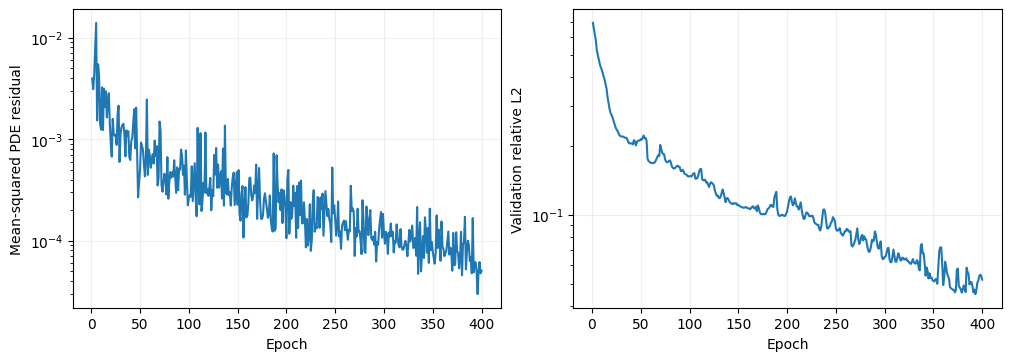

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
axes[0].semilogy(history["epoch"], history["pde_loss"], linewidth=1.5)
axes[0].set(xlabel="Epoch", ylabel="Mean-squared PDE residual")
axes[0].grid(alpha=0.2)
axes[1].semilogy(history["epoch"], history["validation_relative_l2"], linewidth=1.5)
axes[1].set(xlabel="Epoch", ylabel="Validation relative L2")
axes[1].grid(alpha=0.2)
plt.show()


## 5. Independent test and 2D slice


In [8]:
TEST_SAMPLES = 8192
GRID_SIZE = 121

# A separate generator keeps the test set independent of the training budget.
test_generator = torch.Generator(device=DEVICE).manual_seed(SEED + 1)
test_points = sample_points(TEST_SAMPLES, generator=test_generator)
model.eval()
with torch.no_grad():
    test_prediction = model(test_points)
    test_target = exact_solution(test_points)
    test_mse = (test_prediction - test_target).square().mean().item()
    test_relative_l2 = (
        torch.linalg.vector_norm(test_prediction - test_target)
        / torch.linalg.vector_norm(test_target)
    ).item()

axis = torch.linspace(-1, 1, GRID_SIZE, dtype=DTYPE, device=DEVICE)
xx, yy = torch.meshgrid(axis, axis, indexing="ij")
slice_points = torch.zeros(GRID_SIZE**2, DIMENSION, dtype=DTYPE, device=DEVICE)
slice_points[:, 0], slice_points[:, 1] = xx.reshape(-1), yy.reshape(-1)
with torch.no_grad():
    exact_slice = exact_solution(slice_points).reshape(GRID_SIZE, GRID_SIZE).cpu()
    predicted_slice = model(slice_points).reshape(GRID_SIZE, GRID_SIZE).cpu()
slice_error = predicted_slice - exact_slice


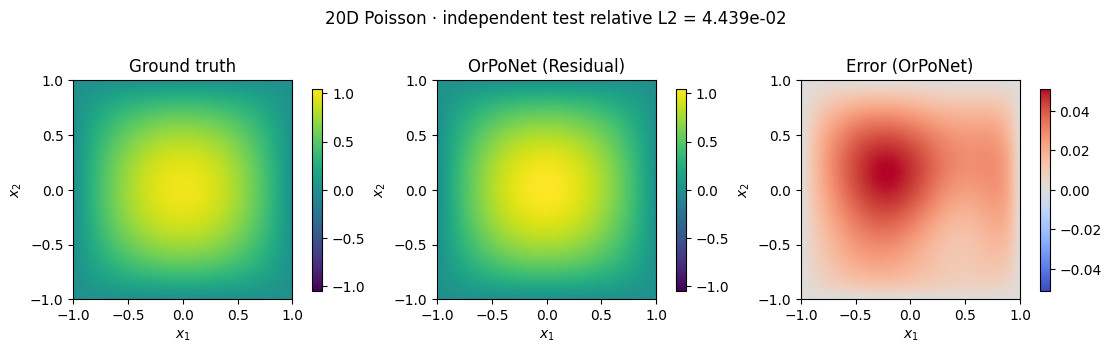

In [9]:
value_limit = max(exact_slice.abs().max().item(), predicted_slice.abs().max().item())
error_limit = max(slice_error.abs().max().item(), 1e-12)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), constrained_layout=True)
image = axes[0].imshow(
    exact_slice.T,
    origin="lower",
    extent=[-1, 1, -1, 1],
    cmap="viridis",
    vmin=-value_limit,
    vmax=value_limit,
)
axes[0].set(title="Ground truth", xlabel=r"$x_1$", ylabel=r"$x_2$")
fig.colorbar(image, ax=axes[0], fraction=0.046, pad=0.04)
image = axes[1].imshow(
    predicted_slice.T,
    origin="lower",
    extent=[-1, 1, -1, 1],
    cmap="viridis",
    vmin=-value_limit,
    vmax=value_limit,
)
axes[1].set(title="OrPoNet (Residual)", xlabel=r"$x_1$", ylabel=r"$x_2$")
fig.colorbar(image, ax=axes[1], fraction=0.046, pad=0.04)
image = axes[2].imshow(
    slice_error.T,
    origin="lower",
    extent=[-1, 1, -1, 1],
    cmap="coolwarm",
    vmin=-error_limit,
    vmax=error_limit,
)
axes[2].set(title="Error (OrPoNet)", xlabel=r"$x_1$", ylabel=r"$x_2$")
fig.colorbar(image, ax=axes[2], fraction=0.046, pad=0.04)
fig.suptitle(
    f"{DIMENSION}D Poisson · independent test relative L2 = {test_relative_l2:.3e}"
)
plt.show()
